# LEAD Dataset — EDA & Preprocessing untuk CARLA

**LEAD** (Large-scale Energy Anomaly Detection) adalah dataset konsumsi energi listrik dari 200 gedung selama 2016 (hourly).

Notebook ini:
1. **EDA** — distribusi data, missing values, pola anomali
2. **Preprocessing** — seleksi fitur, imputasi NaN, split train/test per building
3. **Export ke NPY** — format yang siap dipakai CARLA (seperti SMD)

## 0. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path

pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', '{:.4f}'.format)
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True

DATA_DIR  = Path('datasets/LEAD')
OUT_DIR   = DATA_DIR / 'processed'

TRAIN_SPLIT = 0.70   # 70% pertama = train
print('Data dir :', DATA_DIR.resolve())
print('Output   :', OUT_DIR.resolve())

Data dir : D:\CARLA\datasets\LEAD
Output   : D:\CARLA\datasets\LEAD\processed


## 1. Load Data

In [2]:
train_raw = pd.read_csv(DATA_DIR / 'train.csv', parse_dates=['timestamp'])
train_ft  = pd.read_csv(DATA_DIR / 'train_features.csv', parse_dates=['timestamp'])

print('train.csv         :', train_raw.shape)
print('train_features.csv:', train_ft.shape)
train_raw.head(3)

train.csv         : (1749494, 4)
train_features.csv: (1749494, 57)


,building_id,timestamp,meter_reading,anomaly
0,1,2016-01-01,NaN,0
1,32,2016-01-01,NaN,0
2,41,2016-01-01,NaN,0


## 2. EDA — Overview

In [3]:
print('=== Rentang Waktu ===')
print('Start :', train_raw['timestamp'].min())
print('End   :', train_raw['timestamp'].max())

print('\n=== Jumlah Buildings ===')
print('Total buildings :', train_raw['building_id'].nunique())

print('\n=== Distribusi Label Anomali ===')
vc = train_raw['anomaly'].value_counts()
print(vc)
print(f'Anomaly rate    : {vc[1]/vc.sum()*100:.2f}%')

=== Rentang Waktu ===
Start : 2016-01-01 00:00:00
End   : 2016-12-31 23:00:00

=== Jumlah Buildings ===
Total buildings : 200

=== Distribusi Label Anomali ===
anomaly
0    1712198
1      37296
Name: count, dtype: int64
Anomaly rate    : 2.13%


Timestep per building:
count    200.0000
mean    8747.4700
std      152.8465
min     7471.0000
25%     8766.0000
50%     8783.0000
75%     8784.0000
max     8784.0000
dtype: float64


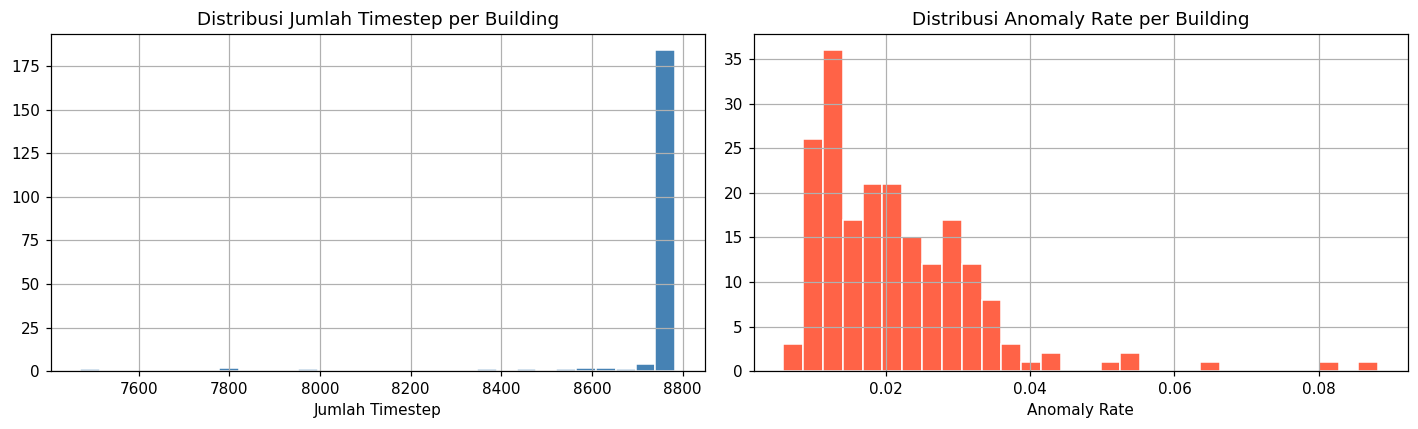

In [4]:
# Statistik jumlah timestep per building
ts_count = train_raw.groupby('building_id').size()
print('Timestep per building:')
print(ts_count.describe())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ts_count.hist(bins=30, ax=axes[0], color='steelblue', edgecolor='white')
axes[0].set_title('Distribusi Jumlah Timestep per Building')
axes[0].set_xlabel('Jumlah Timestep')

anom_ratio = train_raw.groupby('building_id')['anomaly'].mean()
anom_ratio.hist(bins=30, ax=axes[1], color='tomato', edgecolor='white')
axes[1].set_title('Distribusi Anomaly Rate per Building')
axes[1].set_xlabel('Anomaly Rate')
plt.tight_layout()
plt.show()

## 3. EDA — Missing Values

Kolom dengan NaN (%):
meter_reading   6.1534

Building dengan >50% NaN meter_reading: 2


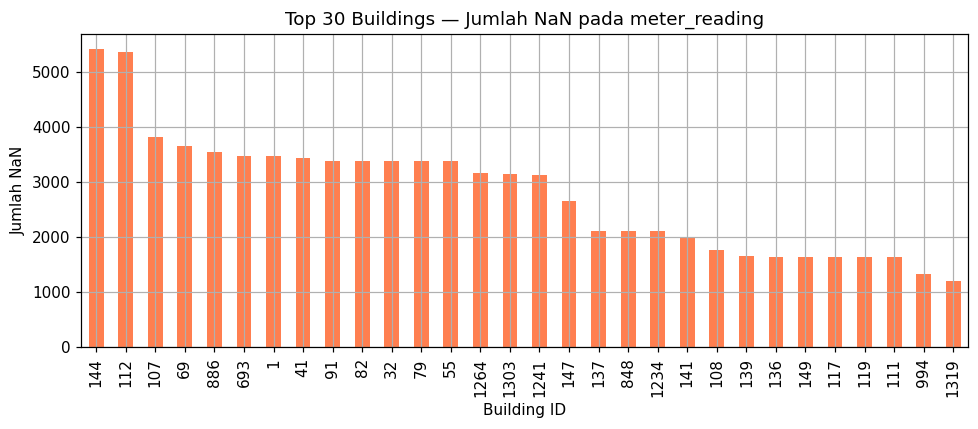

In [5]:
# Missing values pada train_features
nan_pct = train_ft.isnull().mean() * 100
nan_pct = nan_pct[nan_pct > 0].sort_values(ascending=False)
print('Kolom dengan NaN (%):')
print(nan_pct.to_string())

# NaN per building (meter_reading)
nan_bld = train_ft.groupby('building_id')['meter_reading'].apply(lambda x: x.isna().sum())
print(f'\nBuilding dengan >50% NaN meter_reading: {(nan_bld / 8784 > 0.5).sum()}')

fig, ax = plt.subplots(figsize=(9, 4))
nan_bld.sort_values(ascending=False).head(30).plot(kind='bar', ax=ax, color='coral')
ax.set_title('Top 30 Buildings — Jumlah NaN pada meter_reading')
ax.set_xlabel('Building ID')
ax.set_ylabel('Jumlah NaN')
plt.tight_layout()
plt.show()

## 4. EDA — Visualisasi Time Series Sampel

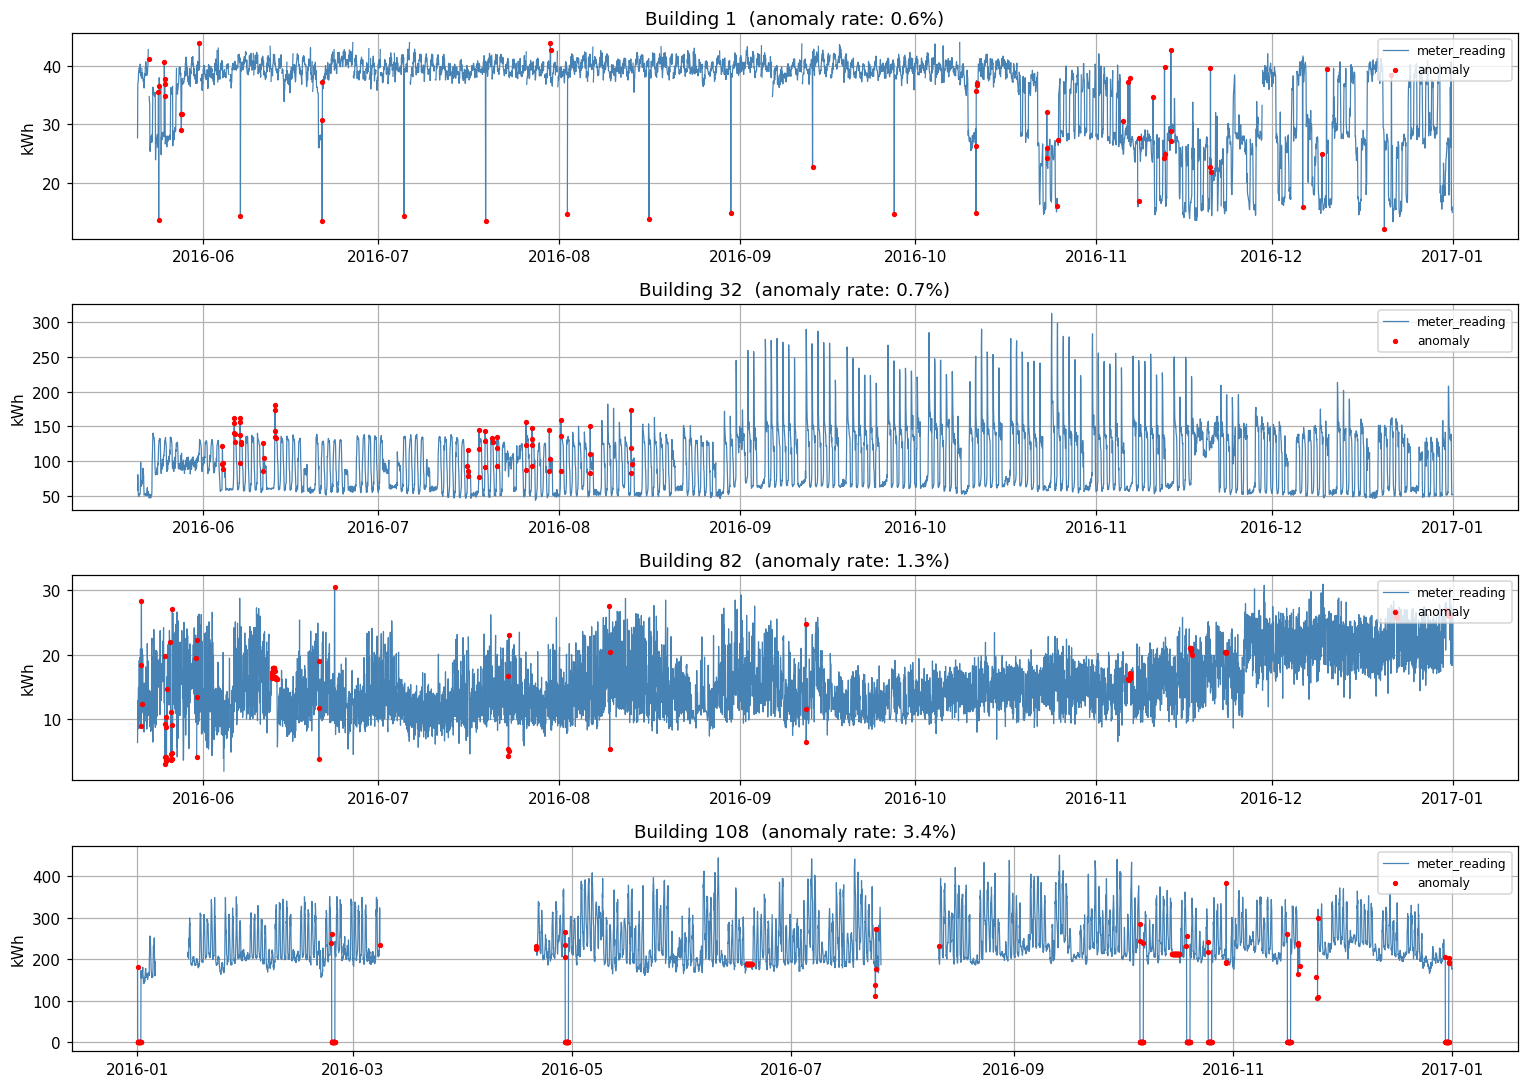

In [6]:
sample_bids = [1, 32, 82, 108]  # sample 4 buildings
fig, axes = plt.subplots(len(sample_bids), 1, figsize=(14, 10), sharex=False)

for ax, bid in zip(axes, sample_bids):
    sub = train_ft[train_ft['building_id'] == bid].sort_values('timestamp')
    ax.plot(sub['timestamp'], sub['meter_reading'], lw=0.8, color='steelblue', label='meter_reading')
    anom = sub[sub['anomaly'] == 1]
    ax.scatter(anom['timestamp'], anom['meter_reading'], color='red', s=6, zorder=5, label='anomaly')
    ax.set_title(f'Building {bid}  (anomaly rate: {sub["anomaly"].mean()*100:.1f}%)')
    ax.set_ylabel('kWh')
    ax.legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()

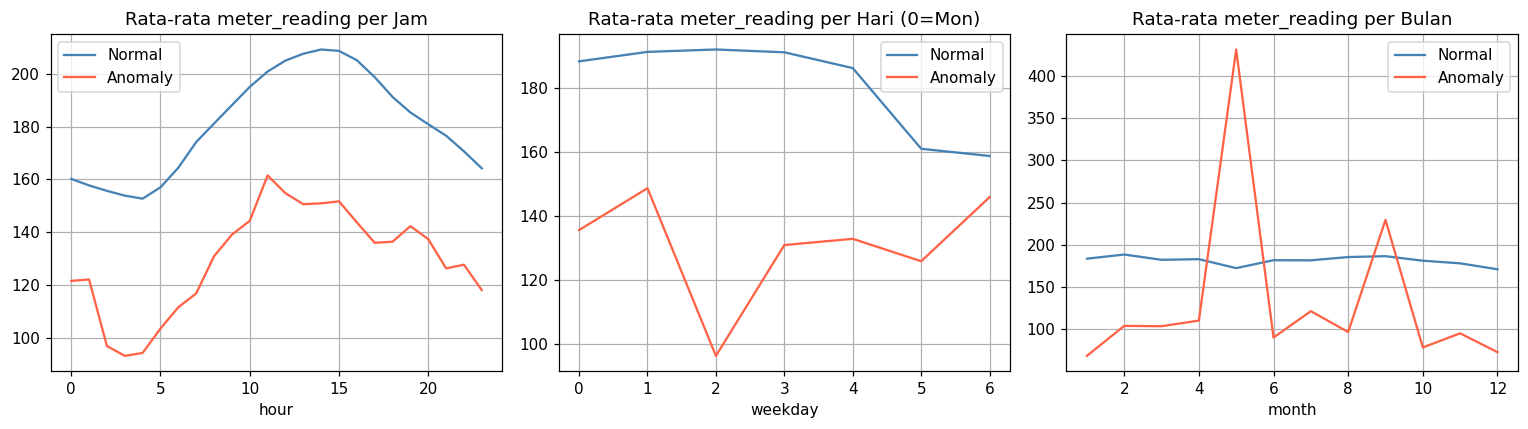

In [7]:
# Pola konsumsi per jam (rata-rata semua building)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

normal = train_ft[train_ft['anomaly'] == 0]
anomal = train_ft[train_ft['anomaly'] == 1]

for ax, col, label in zip(axes,
    ['hour', 'weekday', 'month'],
    ['Jam', 'Hari (0=Mon)', 'Bulan']):
    normal.groupby(col)['meter_reading'].mean().plot(ax=ax, label='Normal', color='steelblue')
    anomal.groupby(col)['meter_reading'].mean().plot(ax=ax, label='Anomaly', color='tomato')
    ax.set_title(f'Rata-rata meter_reading per {label}')
    ax.legend()

plt.tight_layout()
plt.show()

## 5. EDA — Korelasi Fitur dengan Anomali

Jumlah fitur: 39


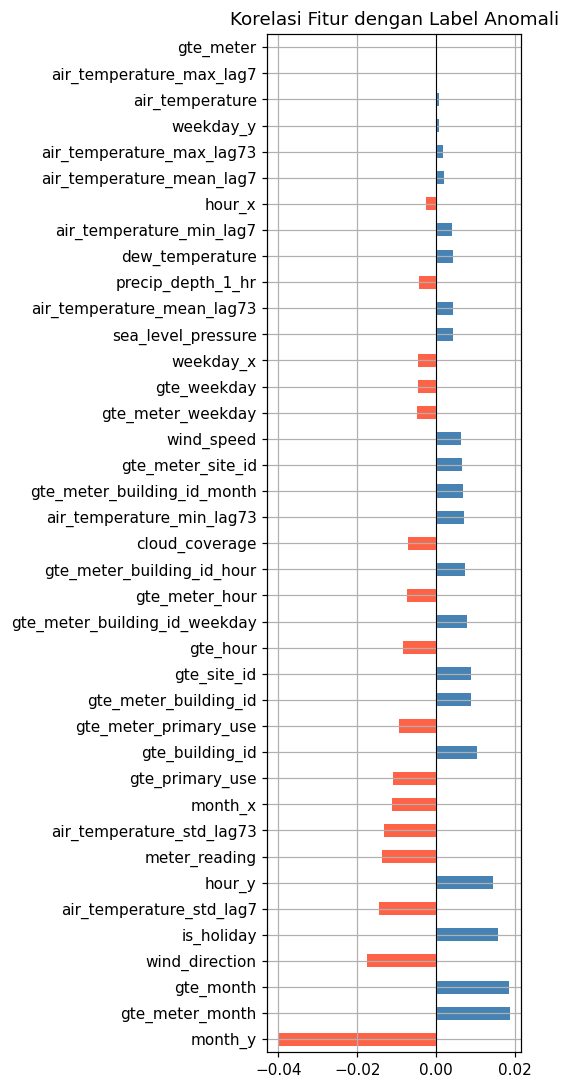

In [8]:
# Fitur numerik yang akan digunakan
NUM_FEATURES = [
    'meter_reading',
    'air_temperature', 'cloud_coverage', 'dew_temperature',
    'precip_depth_1_hr', 'sea_level_pressure', 'wind_direction', 'wind_speed',
    'air_temperature_mean_lag7', 'air_temperature_max_lag7',
    'air_temperature_min_lag7', 'air_temperature_std_lag7',
    'air_temperature_mean_lag73', 'air_temperature_max_lag73',
    'air_temperature_min_lag73', 'air_temperature_std_lag73',
    'hour_x', 'hour_y', 'month_x', 'month_y', 'weekday_x', 'weekday_y',
    'is_holiday',
    'gte_hour', 'gte_weekday', 'gte_month',
    'gte_building_id', 'gte_primary_use', 'gte_site_id', 'gte_meter',
    'gte_meter_hour', 'gte_meter_weekday', 'gte_meter_month',
    'gte_meter_building_id', 'gte_meter_primary_use', 'gte_meter_site_id',
    'gte_meter_building_id_hour', 'gte_meter_building_id_weekday',
    'gte_meter_building_id_month',
]
print(f'Jumlah fitur: {len(NUM_FEATURES)}')

# Korelasi dengan label anomali
sample_df = train_ft.sample(50000, random_state=42)[NUM_FEATURES + ['anomaly']].dropna()
corr = sample_df.corr()['anomaly'].drop('anomaly').sort_values(key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(5, 10))
corr.plot(kind='barh', ax=ax, color=['tomato' if v < 0 else 'steelblue' for v in corr])
ax.set_title('Korelasi Fitur dengan Label Anomali')
ax.axvline(0, color='black', lw=0.7)
plt.tight_layout()
plt.show()

## 6. Preprocessing & Export ke NPY

Struktur output (mengikuti format SMD):
```
datasets/LEAD/processed/
├── train/        {building_id}.npy   shape: (T_train, 39)
├── test/         {building_id}.npy   shape: (T_test, 39)
├── test_label/   {building_id}.npy   shape: (T_test,)  — 0/1
└── building_list.txt
```
Split: 70% awal = train, 30% akhir = test (per building, time-ordered).

In [9]:
for sub in ['train', 'test', 'test_label']:
    (OUT_DIR / sub).mkdir(parents=True, exist_ok=True)

MAX_NAN_RATIO = 0.50   # building dengan >50% NaN meter_reading dilewati

stats = []
skipped = []

building_ids = sorted(train_ft['building_id'].unique())
print(f'Total buildings: {len(building_ids)}')

for bid in building_ids:
    sub = train_ft[train_ft['building_id'] == bid].sort_values('timestamp').reset_index(drop=True)

    # --- Cek kualitas meter_reading ---
    nan_ratio = sub['meter_reading'].isna().mean()
    if nan_ratio > MAX_NAN_RATIO:
        skipped.append((bid, f'NaN ratio={nan_ratio:.1%}'))
        continue

    # --- Ekstrak fitur & label ---
    X = sub[NUM_FEATURES].copy()
    y = sub['anomaly'].values

    # --- Imputasi NaN: forward fill lalu backward fill ---
    X = X.ffill().bfill()
    # Sisa NaN (kolom dengan NaN di awal & akhir sekaligus) → isi 0
    X = X.fillna(0.0)

    X_arr = X.values.astype(np.float32)   # (T, 39)

    # --- Split 70/30 ---
    T = len(X_arr)
    t_split = int(T * TRAIN_SPLIT)

    X_train = X_arr[:t_split]
    X_test  = X_arr[t_split:]
    y_test  = y[t_split:].astype(np.int8)

    # --- Simpan ---
    fname = f'{bid}.npy'
    np.save(OUT_DIR / 'train'      / fname, X_train)
    np.save(OUT_DIR / 'test'       / fname, X_test)
    np.save(OUT_DIR / 'test_label' / fname, y_test)

    stats.append({
        'building_id' : bid,
        'T_total'     : T,
        'T_train'     : len(X_train),
        'T_test'      : len(X_test),
        'anom_total'  : int(y.sum()),
        'anom_test'   : int(y_test.sum()),
        'nan_ratio'   : nan_ratio,
    })

stats_df = pd.DataFrame(stats)
print(f'\nBerhasil  : {len(stats_df)} building')
print(f'Dilewati  : {len(skipped)} building — {skipped[:5]} ...')
print(stats_df.describe())

Total buildings: 200

Berhasil  : 198 building
Dilewati  : 2 building — [(np.int64(112), 'NaN ratio=60.9%'), (np.int64(144), 'NaN ratio=61.6%')] ...
       building_id   T_total   T_train    T_test  anom_total  anom_test  \
count     198.0000  198.0000  198.0000  198.0000    198.0000   198.0000   
mean      798.4747 8747.1010 6122.3687 2624.7323    186.3889    49.6717   
std       409.1659  153.5759  107.4625   46.1144    102.0180    65.2964   
min         1.0000 7471.0000 5229.0000 2242.0000     51.0000     0.0000   
25%       427.0000 8766.0000 6136.0000 2630.0000    111.0000     7.2500   
50%       904.0000 8783.0000 6148.0000 2635.0000    168.5000    30.0000   
75%      1165.7500 8784.0000 6148.0000 2636.0000    239.0000    68.7500   
max      1353.0000 8784.0000 6148.0000 2636.0000    775.0000   568.0000   

       nan_ratio  
count   198.0000  
mean      0.0559  
std       0.1066  
min       0.0000  
25%       0.0013  
50%       0.0167  
75%       0.0341  
max       0.4335  


In [10]:
# Simpan daftar building yang berhasil
building_list = stats_df['building_id'].tolist()
with open(OUT_DIR / 'building_list.txt', 'w') as f:
    for bid in building_list:
        f.write(f'{bid}.npy\n')

print(f'building_list.txt: {len(building_list)} entries')
print('Sample:', building_list[:10])

building_list.txt: 198 entries
Sample: [1, 32, 41, 55, 69, 79, 82, 91, 107, 108]


## 7. Verifikasi

In [11]:
# Spot-check beberapa building
for bid in building_list[:3]:
    tr = np.load(OUT_DIR / 'train'      / f'{bid}.npy')
    te = np.load(OUT_DIR / 'test'       / f'{bid}.npy')
    lb = np.load(OUT_DIR / 'test_label' / f'{bid}.npy')
    print(f'Building {bid:>4}  train:{tr.shape}  test:{te.shape}  '
          f'label:{lb.shape}  anom_rate:{lb.mean()*100:.1f}%  '
          f'NaN train:{np.isnan(tr).sum()}  NaN test:{np.isnan(te).sum()}')

Building    1  train:(6148, 39)  test:(2636, 39)  label:(2636,)  anom_rate:1.2%  NaN train:0  NaN test:0
Building   32  train:(6148, 39)  test:(2636, 39)  label:(2636,)  anom_rate:0.0%  NaN train:0  NaN test:0
Building   41  train:(6148, 39)  test:(2636, 39)  label:(2636,)  anom_rate:1.4%  NaN train:0  NaN test:0


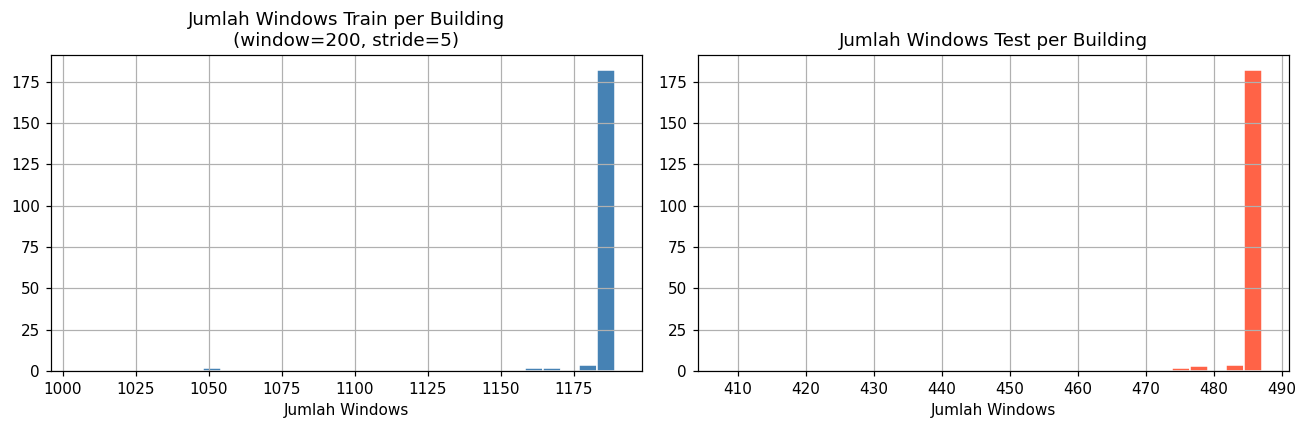


Windows train — min:1005, max:1189, median:1189
Building dengan <50 windows train: 0


In [12]:
# Distribusi windows per building (window_size=200, stride=5)
WS, ST = 200, 5
stats_df['windows_train'] = ((stats_df['T_train'] - WS) / ST).astype(int).clip(lower=0)
stats_df['windows_test']  = ((stats_df['T_test']  - WS) / ST).astype(int).clip(lower=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
stats_df['windows_train'].hist(bins=30, ax=axes[0], color='steelblue', edgecolor='white')
axes[0].set_title('Jumlah Windows Train per Building\n(window=200, stride=5)')
axes[0].set_xlabel('Jumlah Windows')

stats_df['windows_test'].hist(bins=30, ax=axes[1], color='tomato', edgecolor='white')
axes[1].set_title('Jumlah Windows Test per Building')
axes[1].set_xlabel('Jumlah Windows')
plt.tight_layout()
plt.show()

print(f'\nWindows train — min:{stats_df["windows_train"].min()}, '
      f'max:{stats_df["windows_train"].max()}, '
      f'median:{stats_df["windows_train"].median():.0f}')
print(f'Building dengan <50 windows train: '
      f'{(stats_df["windows_train"] < 50).sum()}')

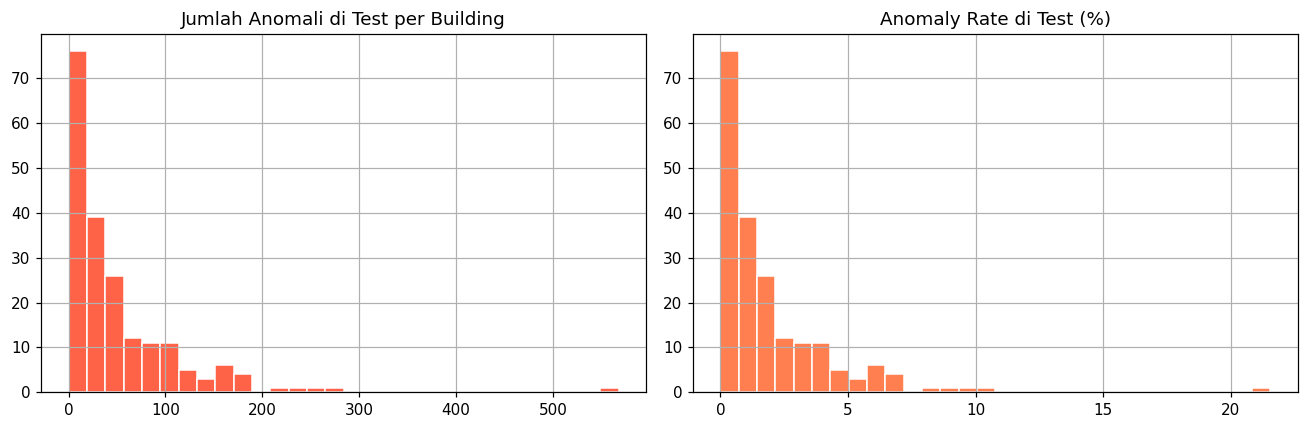

Building tanpa anomali di test: 16


In [13]:
# Distribusi anomali di test set
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
stats_df['anom_test'].hist(bins=30, ax=axes[0], color='tomato', edgecolor='white')
axes[0].set_title('Jumlah Anomali di Test per Building')

(stats_df['anom_test'] / stats_df['T_test'] * 100).hist(
    bins=30, ax=axes[1], color='coral', edgecolor='white')
axes[1].set_title('Anomaly Rate di Test (%)')
plt.tight_layout()
plt.show()

print(f'Building tanpa anomali di test: {(stats_df["anom_test"]==0).sum()}')

## 8. Ringkasan

Data siap dipakai CARLA di:
- `datasets/LEAD/processed/train/{id}.npy`   → (T_train, 39) float32
- `datasets/LEAD/processed/test/{id}.npy`    → (T_test,  39) float32
- `datasets/LEAD/processed/test_label/{id}.npy` → (T_test,)  int8
- `datasets/LEAD/processed/building_list.txt`

Jalankan selanjutnya:
```bash
python run_lead.py --buildings 1.npy            # satu building
python run_lead.py                              # semua building
python evaluate.py --dataset LEAD --channel 1.npy
```